**STEP 1 - Load and Inspect the Dataset**

In [4]:
from google.colab import files

uploaded = files.upload()

Saving HR_Analytics_Cleaned.csv to HR_Analytics_Cleaned (2).csv


In [5]:
import pandas as pd
df = pd.read_csv("HR_Analytics_Cleaned.csv")
print("Shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns)
print("\nDataset Info:")
df.info()

Shape: (1470, 32)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,3,4,1,6,3,3,2,2,2,2



Columns:
Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeNumber',
       'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement',
       'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus',
       'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime',
       'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction',
       'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear',
       'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsSinceLastPromotion', 'YearsWithCurrManager'],
      dtype='object')

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 32 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null  

**STEP 2 — Data Quality Check**

In [6]:
# 1. Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 2. Duplicate employee numbers
print("Duplicate Employee Numbers:",
      df["EmployeeNumber"].duplicated().sum())

# 3. Unique values in every column
print("\nUnique values per column:")
print(df.nunique().sort_values())

# 4. Categorical values
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print("\n", col)
    print(df[col].unique())

# 5. Missing values
print("\nMissing values:")
print(df.isnull().sum())

Duplicate rows: 0
Duplicate Employee Numbers: 0

Unique values per column:
Attrition                      2
Gender                         2
OverTime                       2
PerformanceRating              2
Department                     3
MaritalStatus                  3
BusinessTravel                 3
JobInvolvement                 4
RelationshipSatisfaction       4
JobSatisfaction                4
StockOptionLevel               4
WorkLifeBalance                4
EnvironmentSatisfaction        4
Education                      5
JobLevel                       5
EducationField                 6
TrainingTimesLastYear          7
JobRole                        9
NumCompaniesWorked            10
PercentSalaryHike             15
YearsSinceLastPromotion       16
YearsWithCurrManager          18
YearsInCurrentRole            19
DistanceFromHome              29
YearsAtCompany                37
TotalWorkingYears             40
Age                           43
HourlyRate                    71
D

**STEP 3 — Data Cleaning**

In [7]:
df_clean = df.copy()

In [58]:
df_clean = df_clean.drop(
    columns=["EmployeeCount", "Over18", "StandardHours"]
)

KeyError: "['EmployeeCount', 'Over18', 'StandardHours'] not found in axis"

In [9]:
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (1470, 32)
Cleaned shape: (1470, 32)


In [10]:
print(df_clean.columns.tolist())

['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [11]:
df_clean.to_csv("HR_Analytics_Cleaned.csv", index=False)

In [12]:
from google.colab import files

files.download("HR_Analytics_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**STEP 4 - Basic HR Analysis**

In [14]:
df_clean["Attrition"].value_counts()

,count
Attrition,
No,1233
Yes,237


In [13]:
attrition_rate = (
    (df_clean["Attrition"] == "Yes").sum()
    / len(df_clean)
) * 100

print("Attrition Rate:", round(attrition_rate, 2), "%")

Attrition Rate: 16.12 %


In [15]:
total_employees = len(df_clean)
employees_left = (df_clean["Attrition"] == "Yes").sum()
employees_stayed = (df_clean["Attrition"] == "No").sum()

print("Total Employees :", total_employees)
print("Employees Left  :", employees_left)
print("Employees Stayed:", employees_stayed)
print("Attrition Rate  :", round(attrition_rate, 2), "%")

Total Employees : 1470
Employees Left  : 237
Employees Stayed: 1233
Attrition Rate  : 16.12 %


**STEP 5 - Attrition by Department**

In [16]:
department_attrition = pd.crosstab(
    df_clean["Department"],
    df_clean["Attrition"]
)

department_attrition

Attrition,No,Yes
Department,,
Human Resources,51,12
Research & Development,828,133
Sales,354,92


In [17]:
department_rate = (
    df_clean.groupby("Department")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

print(department_rate)

Department
Human Resources           19.05
Research & Development    13.84
Sales                     20.63
Name: Attrition, dtype: float64


**STEP 6 - Attrition by Job Role**

In [18]:
role_attrition = pd.crosstab(
    df_clean["JobRole"],
    df_clean["Attrition"]
)

role_attrition

Attrition,No,Yes
JobRole,,
Healthcare Representative,122,9
Human Resources,40,12
Laboratory Technician,197,62
Manager,97,5
Manufacturing Director,135,10
Research Director,78,2
Research Scientist,245,47
Sales Executive,269,57
Sales Representative,50,33


In [19]:
role_rate = (
    df_clean.groupby("JobRole")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print(role_rate)

JobRole
Sales Representative         39.76
Laboratory Technician        23.94
Human Resources              23.08
Sales Executive              17.48
Research Scientist           16.10
Manufacturing Director        6.90
Healthcare Representative     6.87
Manager                       4.90
Research Director             2.50
Name: Attrition, dtype: float64


**STEP 7 - Attrition vs Overtime**

In [20]:
overtime_attrition = pd.crosstab(
    df_clean["OverTime"],
    df_clean["Attrition"]
)

overtime_attrition

Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127


In [21]:
overtime_rate = (
    df_clean.groupby("OverTime")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

print(overtime_rate)

OverTime
No     10.44
Yes    30.53
Name: Attrition, dtype: float64


**STEP 8 - Attrition vs Job Satisfaction**

In [22]:
satisfaction_attrition = pd.crosstab(
    df_clean["JobSatisfaction"],
    df_clean["Attrition"]
)

satisfaction_attrition

Attrition,No,Yes
JobSatisfaction,,
1,223,66
2,234,46
3,369,73
4,407,52


In [23]:
satisfaction_rate = (
    df_clean.groupby("JobSatisfaction")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

print(satisfaction_rate)

JobSatisfaction
1    22.84
2    16.43
3    16.52
4    11.33
Name: Attrition, dtype: float64


**STEP 9 - Attrition vs Work-Life Balance**

In [24]:
worklife_attrition = pd.crosstab(
    df_clean["WorkLifeBalance"],
    df_clean["Attrition"]
)

worklife_attrition

Attrition,No,Yes
WorkLifeBalance,,
1,55,25
2,286,58
3,766,127
4,126,27


In [25]:
worklife_rate = (
    df_clean.groupby("WorkLifeBalance")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

print(worklife_rate)

WorkLifeBalance
1    31.25
2    16.86
3    14.22
4    17.65
Name: Attrition, dtype: float64


**STEP 10 - Attrition vs Age**

In [26]:
df_clean["AgeGroup"] = pd.cut(
    df_clean["Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["Under 25", "25-34", "35-44", "45-54", "55+"]
)

In [27]:
df_clean["AgeGroup"].value_counts().sort_index()

,count
AgeGroup,
Under 25,123
25-34,606
35-44,468
45-54,226
55+,47


In [28]:
age_attrition = (
    df_clean.groupby("AgeGroup", observed=True)["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

print(age_attrition)

AgeGroup
Under 25    35.77
25-34       19.14
35-44        9.19
45-54       11.50
55+         17.02
Name: Attrition, dtype: float64


**STEP 11 - Attrition vs Tenure**

In [29]:
df_clean["TenureGroup"] = pd.cut(
    df_clean["YearsAtCompany"],
    bins=[-1, 2, 5, 10, 20, 100],
    labels=["0-2 Years", "3-5 Years", "6-10 Years", "11-20 Years", "20+ Years"]
)

In [31]:
df_clean["TenureGroup"].value_counts().sort_index()

,count
TenureGroup,
0-2 Years,342
3-5 Years,434
6-10 Years,448
11-20 Years,180
20+ Years,66


In [32]:
tenure_attrition = (
    df_clean.groupby("TenureGroup", observed=True)["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

print(tenure_attrition)

TenureGroup
0-2 Years      29.82
3-5 Years      13.82
6-10 Years     12.28
11-20 Years     6.67
20+ Years      12.12
Name: Attrition, dtype: float64


**STEP 12 - Attrition vs Monthly Income**

In [33]:
df_clean["IncomeGroup"] = pd.cut(
    df_clean["MonthlyIncome"],
    bins=[0, 3000, 6000, 10000, 15000, float("inf")],
    labels=[
        "Below 3000",
        "3000-5999",
        "6000-9999",
        "10000-14999",
        "15000+"
    ]
)

In [ ]:
df_clean["IncomeGroup"].value_counts().sort_index()

In [ ]:
income_attrition = (
    df_clean.groupby("IncomeGroup", observed=True)["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

print(income_attrition)

**STEP 13 - Performance vs Salary**

In [ ]:
df_clean["PerformanceRating"].value_counts().sort_index()

In [34]:
performance_salary = (
    df_clean.groupby("PerformanceRating")["MonthlyIncome"]
    .agg(["count", "mean", "min", "max"])
    .round(2)
)

performance_salary

,count,mean,min,max
PerformanceRating,,,,
3,1244,6537.27,1009,19999
4,226,6313.89,1052,19973


**STEP 14 - Promotion & Career Growth**

In [35]:
career_growth = (
    df_clean.groupby("Attrition")[
        ["YearsSinceLastPromotion",
         "YearsInCurrentRole",
         "YearsAtCompany"]
    ]
    .mean()
    .round(2)
)

career_growth

,YearsSinceLastPromotion,YearsInCurrentRole,YearsAtCompany
Attrition,,,
No,2.23,4.48,7.37
Yes,1.95,2.90,5.13


**STEP 15 - Diversity Analysis**

In [36]:
gender_attrition = pd.crosstab(
    df_clean["Gender"],
    df_clean["Attrition"]
)

gender_attrition

Attrition,No,Yes
Gender,,
Female,501,87
Male,732,150


In [37]:
gender_rate = (
    df_clean.groupby("Gender")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

print(gender_rate)

Gender
Female    14.80
Male      17.01
Name: Attrition, dtype: float64


**STEP 15B - Education Analysis**

In [38]:
education_attrition = pd.crosstab(
    df_clean["EducationField"],
    df_clean["Attrition"]
)

education_attrition

Attrition,No,Yes
EducationField,,
Human Resources,20,7
Life Sciences,517,89
Marketing,124,35
Medical,401,63
Other,71,11
Technical Degree,100,32


In [39]:
education_rate = (
    df_clean.groupby("EducationField")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print(education_rate)

EducationField
Human Resources     25.93
Technical Degree    24.24
Marketing           22.01
Life Sciences       14.69
Medical             13.58
Other               13.41
Name: Attrition, dtype: float64


**STEP 16 - Attrition vs Business Travel**

In [40]:
travel_attrition = pd.crosstab(
    df_clean["BusinessTravel"],
    df_clean["Attrition"]
)

travel_attrition

Attrition,No,Yes
BusinessTravel,,
Non-Travel,138,12
Travel_Frequently,208,69
Travel_Rarely,887,156


In [41]:
travel_rate = (
    df_clean.groupby("BusinessTravel")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print(travel_rate)

BusinessTravel
Travel_Frequently    24.91
Travel_Rarely        14.96
Non-Travel            8.00
Name: Attrition, dtype: float64


**STEP 17 - Attrition vs Marital Status**

In [42]:
marital_attrition = pd.crosstab(
    df_clean["MaritalStatus"],
    df_clean["Attrition"]
)

marital_attrition

Attrition,No,Yes
MaritalStatus,,
Divorced,294,33
Married,589,84
Single,350,120


In [43]:
marital_rate = (
    df_clean.groupby("MaritalStatus")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print(marital_rate)

MaritalStatus
Single      25.53
Married     12.48
Divorced    10.09
Name: Attrition, dtype: float64


**STEP 18 - Final HR KPI Summary**

In [44]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Employees",
        "Employees Left",
        "Employees Stayed",
        "Attrition Rate",
        "Average Age",
        "Average Monthly Income",
        "Average Years at Company",
        "Average Job Satisfaction"
    ],
    "Value": [
        len(df_clean),
        (df_clean["Attrition"] == "Yes").sum(),
        (df_clean["Attrition"] == "No").sum(),
        round((df_clean["Attrition"] == "Yes").mean() * 100, 2),
        round(df_clean["Age"].mean(), 2),
        round(df_clean["MonthlyIncome"].mean(), 2),
        round(df_clean["YearsAtCompany"].mean(), 2),
        round(df_clean["JobSatisfaction"].mean(), 2)
    ]
})

kpi_summary

,KPI,Value
0,Total Employees,1470.00
1,Employees Left,237.00
2,Employees Stayed,1233.00
3,Attrition Rate,16.12
4,Average Age,36.92
5,Average Monthly Income,6502.93
6,Average Years at Company,7.01
7,Average Job Satisfaction,2.73


**STEP 19 - Create Our First Visualizations**

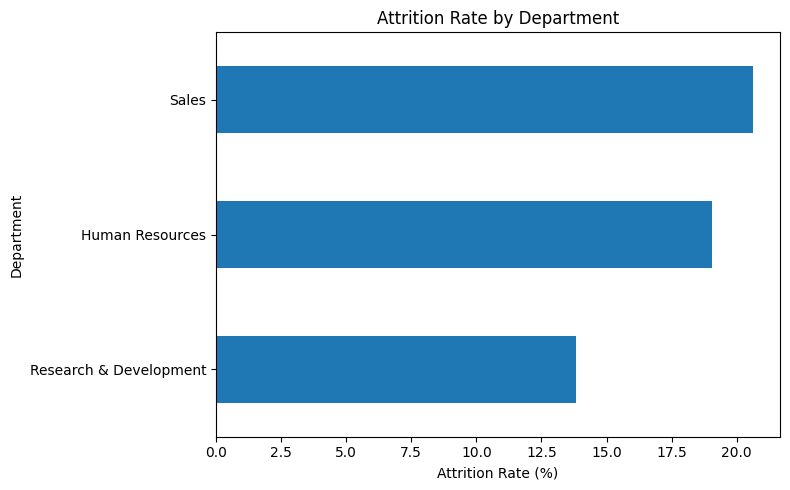

In [45]:
import matplotlib.pyplot as plt

department_rate.sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Attrition Rate by Department")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Department")
plt.tight_layout()
plt.show()

**STEP 19.2 - Attrition by Job Role**

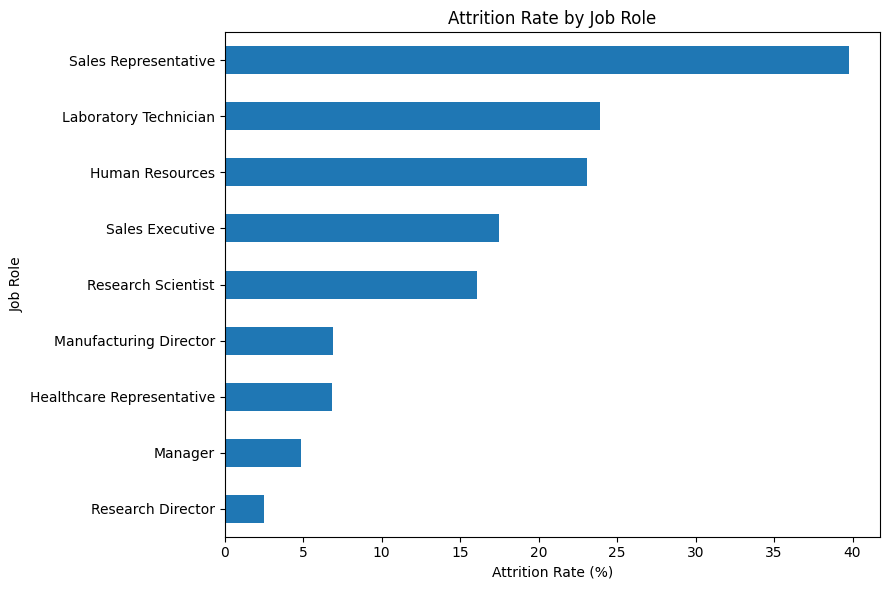

In [46]:
plt.figure(figsize=(9, 6))

role_rate.sort_values().plot(
    kind="barh"
)

plt.title("Attrition Rate by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")
plt.tight_layout()
plt.show()

**STEP 19.3 - Attrition vs Overtime Chart**

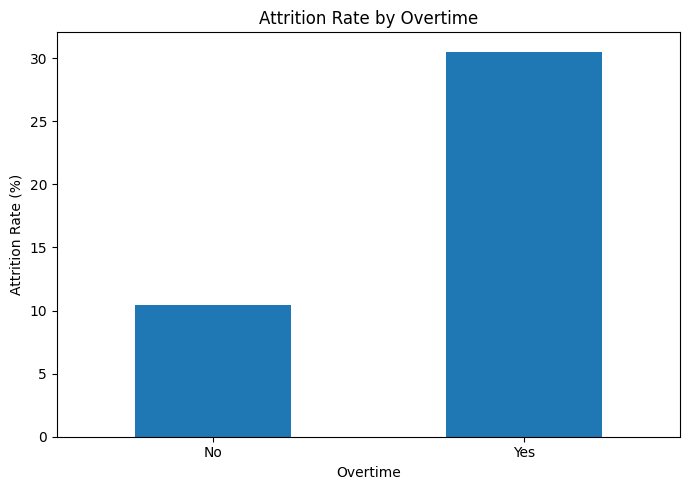

In [47]:
import matplotlib.pyplot as plt

overtime_rate.sort_values().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Attrition Rate by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**STEP 19.4 - Attrition vs Job Satisfaction**

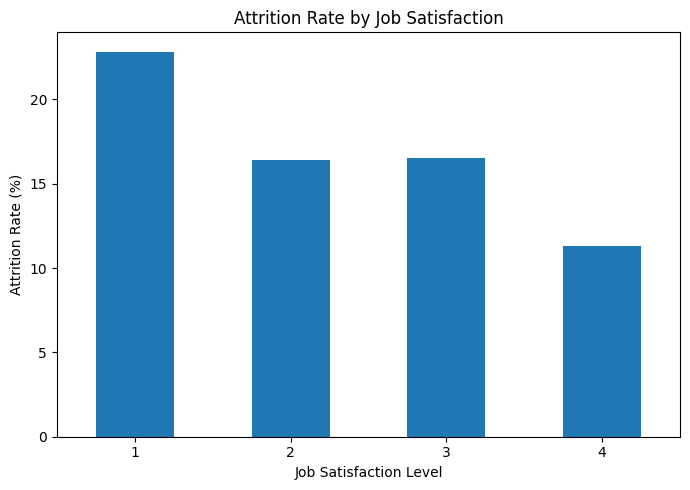

In [48]:
plt.figure(figsize=(7, 5))

satisfaction_rate.plot(
    kind="bar"
)

plt.title("Attrition Rate by Job Satisfaction")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**STEP 19.5 - Attrition vs Work-Life Balance**

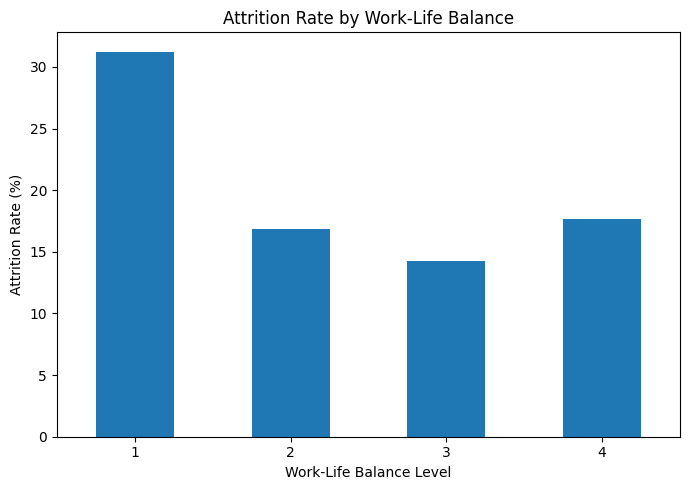

In [49]:
plt.figure(figsize=(7, 5))

worklife_rate.plot(
    kind="bar"
)

plt.title("Attrition Rate by Work-Life Balance")
plt.xlabel("Work-Life Balance Level")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**STEP 19.6 - Attrition vs Age Group**

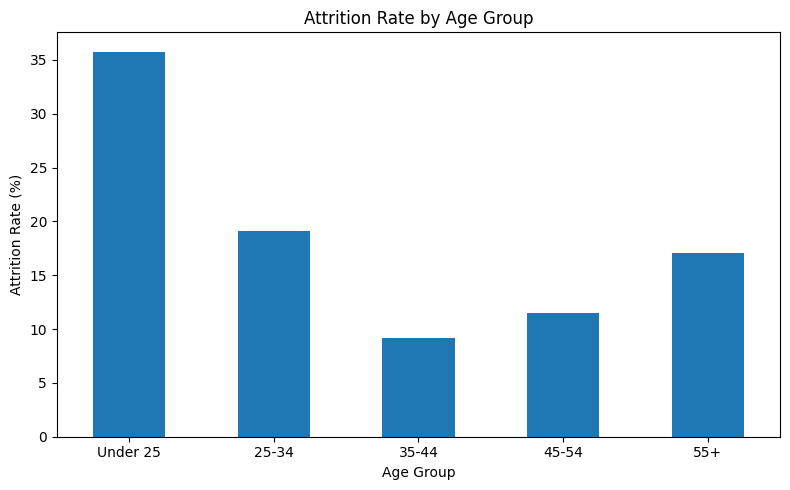

In [50]:
plt.figure(figsize=(8, 5))

age_attrition.plot(
    kind="bar"
)

plt.title("Attrition Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**STEP 19.7 - Attrition vs Tenure**

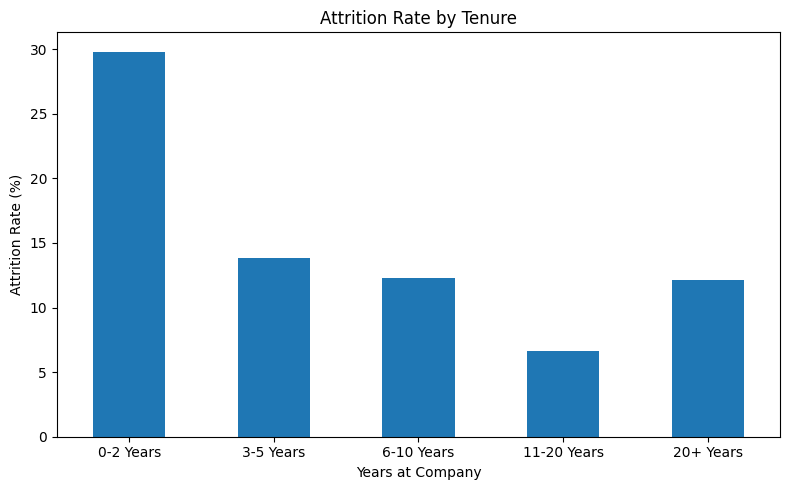

In [51]:
plt.figure(figsize=(8, 5))

tenure_attrition.plot(
    kind="bar"
)

plt.title("Attrition Rate by Tenure")
plt.xlabel("Years at Company")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**STEP 19.8 - Attrition vs Monthly Income**

In [54]:
plt.figure(figsize=(8, 5))

income_attrition.plot(
    kind="bar"
)

plt.title("Attrition Rate by Monthly Income")
plt.xlabel("Monthly Income Group")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

NameError: name 'income_attrition' is not defined

<Figure size 800x500 with 0 Axes>

**STEP 19.9 - Performance vs Salary**

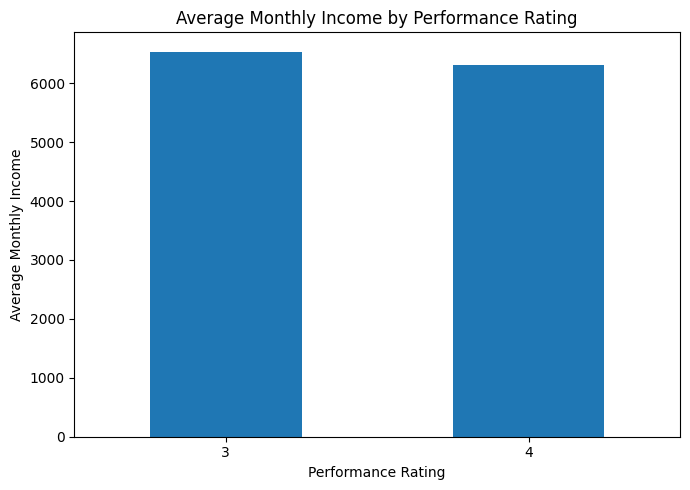

In [53]:
plt.figure(figsize=(7, 5))

performance_salary["mean"].plot(
    kind="bar"
)

plt.title("Average Monthly Income by Performance Rating")
plt.xlabel("Performance Rating")
plt.ylabel("Average Monthly Income")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**STEP 20 - Final Dataset Preparation**

In [55]:
print("Final Shape:", df_clean.shape)

print("\nFinal Columns:")
print(df_clean.columns.tolist())

Final Shape: (1470, 35)

Final Columns:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'AgeGroup', 'TenureGroup', 'IncomeGroup']


In [56]:
df_clean[
    ["AgeGroup", "TenureGroup", "IncomeGroup"]
].head()

,AgeGroup,TenureGroup,IncomeGroup
0,35-44,6-10 Years,3000-5999
1,45-54,6-10 Years,3000-5999
2,35-44,0-2 Years,Below 3000
3,25-34,6-10 Years,Below 3000
4,25-34,0-2 Years,3000-5999


In [57]:
print("Total missing values:", df_clean.isnull().sum().sum())

Total missing values: 0


In [ ]:
df_clean.to_csv("HR_Analytics_Final.csv", index=False)

In [ ]:
from google.colab import files

files.download("HR_Analytics_Final.csv")